## Simple MultiAI Agent Architecture


In [1]:
import os
from typing import TypedDict, Annotated, List, Literal
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain_tavily import TavilySearch
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver

C:\Users\pc\AppData\Local\Temp\ipykernel_23976\522456642.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")

In [3]:
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

In [4]:
## Define the state
class AgentState(MessagesState):
    next_agent:str #ehich agent should go next 

In [5]:
# Create simple tools
@tool
def search_web(query: str) -> str:
    """Search the web for information."""
    # Using Tavily for web search
    search = TavilySearch(max_results=3)
    results = search.invoke(query)
    return str(results)

@tool
def write_summary(content: str) -> str:
    """Write a summary of the provided content."""
    # Simple summary generation
    summary = f"Summary of findings:\n\n{content[:500]}..."
    return summary

In [6]:
from langchain.chat_models import init_chat_model

llm = init_chat_model(
    "openai/gpt-oss-20b",
    model_provider="groq"
)

llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001B6AC7396A0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001B6AC739FD0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [7]:
# Define agent functions (simpler approach)
def researcher_agent(state: AgentState):
    """Researcher agent that searches for information"""
    
    messages = state["messages"]
    
    # Add system message for context
    system_msg = SystemMessage(content="You are a research assistant. Use the search_web tool to find information about the user's request.")
    
    # Call LLM with tools
    researcher_llm = llm.bind_tools([search_web])
    response = researcher_llm.invoke([system_msg] + messages)
    
    # Return the response and route to writer
    return {
        "messages": [response],
        "next_agent": "writer"
    }

In [8]:
def writer_agent(state: AgentState):
    """Writer agent that creates summaries"""
    
    messages = state["messages"]
    
    # Add system message
    system_msg = SystemMessage(content="You are a technical writer. Review the conversation and create a clear, concise summary of the findings.")
    
    # Simple completion without tools
    response = llm.invoke([system_msg] + messages)
    
    return {
        "messages": [response],
        "next_agent": "end"
    }

In [9]:
# Route the researcher to Tavily when it requests a tool call.
def route_researcher(state: MessagesState):
    last_message = state["messages"][-1]
    if getattr(last_message, "tool_calls", None):
        return "tools"
    return "writer"

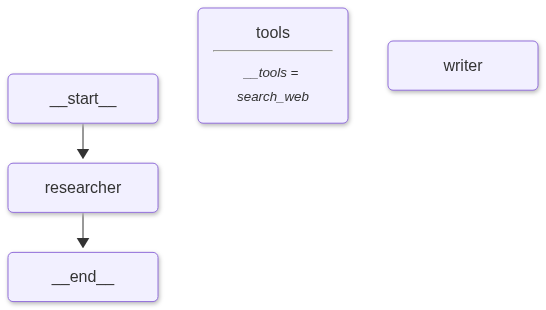

In [10]:
# Build graph
workflow = StateGraph(MessagesState)

# Add nodes
workflow.add_node("researcher", researcher_agent)
workflow.add_node("tools", ToolNode([search_web]))
workflow.add_node("writer", writer_agent)

# Define flow
workflow.set_entry_point("researcher")
workflow.add_conditional_edges("researcher", route_researcher)
workflow.add_edge("tools", "researcher")
workflow.add_edge("writer", END)
final_workflow=workflow.compile()

final_workflow

In [11]:
response=final_workflow.invoke({"messages":"Reasearch about the usecase of agentic ai in business"})

In [12]:
ans = response["messages"][-1].content
print(ans)

**Agentic AI in Business – Key Findings**

| Area | Typical Use Cases | Business Impact |
|------|------------------|-----------------|
| **Customer Service** | • Auto‑routing tickets<br>• Proactive resolution suggestions | 30–50 % faster first‑contact resolution (Hyland) |
| **Sales & Revenue Ops** | • Lead scoring & prioritization<br>• Guided selling & contract automation | 20–30 % lift in close rate (Bain) |
| **Marketing Ops** | • Campaign orchestration across platforms<br>• Real‑time personalization | 40–60 % faster launch, 15–20 % higher ROI (MoveWorks) |
| **Finance & Accounting** | • Invoice‑to‑pay automation<br>• KYC/AML checks | 25–35 % processing‑time reduction, 10–15 % cost savings (Hyland) |
| **Human Resources** | • Benefits enrollment & life‑event processing | 50–70 % admin‑time cut |
| **Supply Chain & Ops** | • Demand‑forecast inventory control<br>• Dynamic route optimisation | 10–20 % throughput gains (Boomi) |
| **IT & Security** | • Automated threat detection & tick

## supervise Multi Ai Agent Architecture

In [13]:
from typing import TypedDict, Annotated, List, Literal, Dict, Any
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.checkpoint.memory import MemorySaver
import random
from datetime import datetime

In [14]:
# ===================================
# State Definition
# ===================================

# ===================================
# State Definition
# ===================================

class SupervisorState(MessagesState):
    """State for the multi-agent system"""
    next_agent: str = ""
    research_data: str = ""
    analysis: str = ""
    final_report: str = ""
    task_complete: bool = False
    current_task: str = ""

In [15]:
# ===================================
# Supervisor with Groq LLM
# ===================================
from langchain_core.prompts import ChatPromptTemplate
def create_supervisor_chain():
    """Creates the supervisor decision chain"""
    
    supervisor_prompt = ChatPromptTemplate.from_messages([
        ("system", """You are a supervisor managing a team of agents:
        
1. Researcher - Gathers information and data
2. Analyst - Analyzes data and provides insights  
3. Writer - Creates reports and summaries

Based on the current state and conversation, decide which agent should work next.
If the task is complete, respond with 'DONE'.

Current state:
- Has research data: {has_research}
- Has analysis: {has_analysis}
- Has report: {has_report}

Respond with ONLY the agent name (researcher/analyst/writer) or 'DONE'.
"""),
        ("human", "{task}")
    ])
    
    return supervisor_prompt | llm

In [16]:
def supervisor_agent(state: SupervisorState) -> Dict:
    """Supervisor decides next agent using Groq LLM"""
    
    messages = state["messages"]
    task = state.get("current_task") or (messages[-1].content if messages else "No task")
    
    # Check what's been completed
    has_research = bool(state.get("research_data", ""))
    has_analysis = bool(state.get("analysis", ""))
    has_report = bool(state.get("final_report", ""))
    
    # Get LLM decision
    chain = create_supervisor_chain()
    decision = chain.invoke({
        "task": task,
        "has_research": has_research,
        "has_analysis": has_analysis,
        "has_report": has_report
    })
    
    # Parse decision
    decision_text = decision.content.strip().lower()
    print(decision_text)
    
    # Determine next agent
    if "done" in decision_text or has_report:
        next_agent = "end"
        supervisor_msg = "✅ Supervisor: All tasks complete! Great work team."
    elif "researcher" in decision_text or not has_research:
        next_agent = "researcher"
        supervisor_msg = "📋 Supervisor: Let's start with research. Assigning to Researcher..."
    elif "analyst" in decision_text or (has_research and not has_analysis):
        next_agent = "analyst"
        supervisor_msg = "📋 Supervisor: Research done. Time for analysis. Assigning to Analyst..."
    elif "writer" in decision_text or (has_analysis and not has_report):
        next_agent = "writer"
        supervisor_msg = "📋 Supervisor: Analysis complete. Let's create the report. Assigning to Writer..."
    else:
        next_agent = "end"
        supervisor_msg = "✅ Supervisor: Task seems complete."
    
    return {
        "messages": [AIMessage(content=supervisor_msg)],
        "next_agent": next_agent,
        "current_task": task
    }

In [17]:
# ===================================
# Agent 1: Researcher (using Groq)
# ===================================

def researcher_agent(state: SupervisorState) -> Dict:
    """Researcher uses Groq to gather information"""
    
    task = state.get("current_task", "research topic")
    
    # Create research prompt
    research_prompt = f"""As a research specialist, provide comprehensive information about: {task}

    Include:
    1. Key facts and background
    2. Current trends or developments
    3. Important statistics or data points
    4. Notable examples or case studies
    
    Be concise but thorough."""
    
    # Get research from LLM
    research_response = llm.invoke([HumanMessage(content=research_prompt)])
    research_data = research_response.content
    
    # Create agent message
    agent_message = f"🔍 Researcher: I've completed the research on '{task}'.\n\nKey findings:\n{research_data[:500]}..."
    
    return {
        "messages": [AIMessage(content=agent_message)],
        "research_data": research_data,
        "next_agent": "supervisor"
    }

In [18]:
# ===================================
# Agent 2: Analyst (using Groq)
# ===================================

def analyst_agent(state: SupervisorState) -> Dict:
    """Analyst uses Groq to analyze the research"""
    
    research_data = state.get("research_data", "")
    task = state.get("current_task", "")
    
    # Create analysis prompt
    analysis_prompt = f"""As a data analyst, analyze this research data and provide insights:

Research Data:
{research_data}

Provide:
1. Key insights and patterns
2. Strategic implications
3. Risks and opportunities
4. Recommendations

Focus on actionable insights related to: {task}"""
    
    # Get analysis from LLM
    analysis_response = llm.invoke([HumanMessage(content=analysis_prompt)])
    analysis = analysis_response.content
    
    # Create agent message
    agent_message = f"📊 Analyst: I've completed the analysis.\n\nTop insights:\n{analysis[:400]}..."
    
    return {
        "messages": [AIMessage(content=agent_message)],
        "analysis": analysis,
        "next_agent": "supervisor"
    }

In [19]:
# ===================================
# Agent 3: Writer (using Groq)
# ===================================

def writer_agent(state: SupervisorState) -> Dict:
    """Writer uses Groq to create final report"""
    
    research_data = state.get("research_data", "")
    analysis = state.get("analysis", "")
    task = state.get("current_task", "")
    
    # Create writing prompt
    writing_prompt = f"""As a professional writer, create an executive report based on:

Task: {task}

Research Findings:
{research_data[:1000]}

Analysis:
{analysis[:1000]}

Create a well-structured report with:
1. Executive Summary
2. Key Findings  
3. Analysis & Insights
4. Recommendations
5. Conclusion

Keep it professional and concise."""
    
    # Get report from LLM
    report_response = llm.invoke([HumanMessage(content=writing_prompt)])
    report = report_response.content
    
    # Create final formatted report
    final_report = f"""
📄 FINAL REPORT
{'='*50}
Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}
Topic: {task}
{'='*50}

{report}

{'='*50}
Report compiled by Multi-Agent AI System powered by Groq
"""
    
    return {
        "messages": [AIMessage(content=f"✍️ Writer: Report complete! See below for the full document.")],
        "final_report": final_report,
        "next_agent": "supervisor",
        "task_complete": True
    }

In [20]:
# ===================================
# Router Function
# ===================================

def router(state: SupervisorState) -> Literal["supervisor", "researcher", "analyst", "writer", "__end__"]:
    """Routes to next agent based on state"""
    
    next_agent = state.get("next_agent", "supervisor")
    
    if next_agent == "end" or state.get("task_complete", False):
        return END
        
    if next_agent in ["supervisor", "researcher", "analyst", "writer"]:
        return next_agent
        
    return "supervisor"

In [21]:
# Create workflow
workflow = StateGraph(SupervisorState)

# Add nodes
workflow.add_node("supervisor", supervisor_agent)
workflow.add_node("researcher", researcher_agent)
workflow.add_node("analyst", analyst_agent)
workflow.add_node("writer", writer_agent)

# Set entry point
workflow.set_entry_point("supervisor")

# Add routing
for node in ["supervisor", "researcher", "analyst", "writer"]:
    workflow.add_conditional_edges(
        node,
        router,
        {
            "supervisor": "supervisor",
            "researcher": "researcher",
            "analyst": "analyst",
            "writer": "writer",
            END: END
        }
    )

graph=workflow.compile()

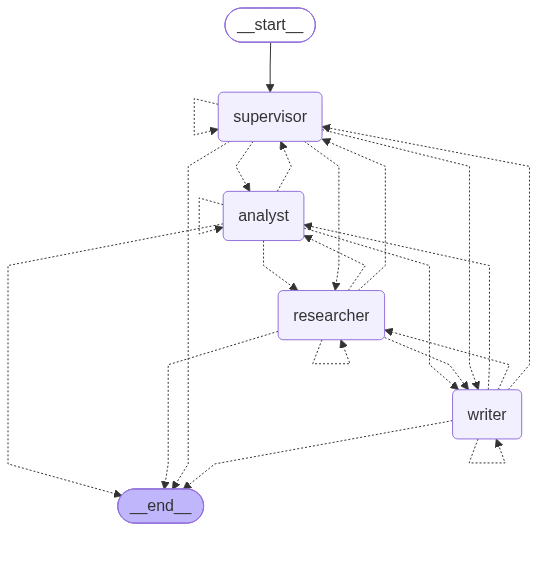

In [22]:
graph

In [23]:
topic = "What are the benefits and risks of AI in healthcare?"

response = graph.invoke({
    "messages": [HumanMessage(content=topic)],
    "next_agent": "supervisor",
    "research_data": "",
    "analysis": "",
    "final_report": "",
    "task_complete": False,
    "current_task": topic
})

researcher
analyst
writer


In [24]:
print(response["final_report"])



📄 FINAL REPORT
Generated: 2026-11-21 11:08
Topic: What are the benefits and risks of AI in healthcare?

**Executive Report**  
**The Benefits and Risks of Artificial Intelligence in Healthcare**  
*Prepared for: Executive Leadership Team*  
*Date: 21 November 2026*  

---

## 1. Executive Summary  

Artificial intelligence (AI) has transitioned from academic curiosity to a commercial cornerstone of modern health‑care delivery.  By 2026, the global AI‑in‑health‑care market is projected at **$45 billion** with a **CAGR of 42 %**.  Key evidence demonstrates that AI can improve diagnostic accuracy, reduce costs, and accelerate drug discovery.  However, the technology also introduces significant risks—algorithmic bias, privacy breaches, regulatory uncertainty, and diminished clinician trust.  

**Bottom line:** Deploying AI responsibly offers *high‑impact, high‑value* opportunities, but only if accompanied by rigorous governance, bias mitigation, and transparent communication with stakehol

## Simple Hierarchical Multi-Agent System with Groq

In [25]:
from typing import Dict, Literal
from langchain_core.messages import HumanMessage, AIMessage
from langchain_core.prompts import ChatPromptTemplate
from langgraph.graph import StateGraph, END, MessagesState
from datetime import datetime

In [26]:
class HierarchicalState(MessagesState):
    """State shared by the CEO, team leaders, and specialist agents."""
    next_node: str = ""
    current_task: str = ""
    data_research: str = ""
    market_research: str = ""
    research_team_output: str = ""
    technical_report: str = ""
    summary_report: str = ""
    writing_team_output: str = ""
    final_output: str = ""
    task_complete: bool = False

In [27]:
def create_ceo_chain():
    prompt = ChatPromptTemplate.from_messages([
        ("system", """You are the CEO of a hierarchical AI organization.
You manage two team leaders:
1. Research Team Leader
2. Writing Team Leader

Current state:
- Has research: {has_research}
- Has writing: {has_writing}

Respond with ONLY one value:
- research_team
- writing_team
- done"""),
        ("human", "{task}")
    ])
    return prompt | llm


def ceo_agent(state: HierarchicalState) -> Dict:
    """Top-level CEO decides which team to assign work to."""
    task = state.get("current_task", "")
    has_research = bool(state.get("research_team_output", ""))
    has_writing = bool(state.get("writing_team_output", ""))

    if has_writing:
        next_node = "end"
        message = "CEO: The complete hierarchical report is ready."
    elif not has_research:
        next_node = "research_team_leader"
        message = "CEO: Assigning the task to the Research Team Leader."
    else:
        next_node = "writing_team_leader"
        message = "CEO: Research is complete. Assigning writing to the Writing Team Leader."

    return {
        "messages": [AIMessage(content=message)],
        "next_node": next_node,
        "current_task": task
    }

In [28]:
def create_research_leader_chain():
    prompt = ChatPromptTemplate.from_messages([
        ("system", """You are the Research Team Leader.
Manage these specialists:
1. Data Researcher
2. Market Researcher

Current state:
- Has data research: {has_data_research}
- Has market research: {has_market_research}

Respond with ONLY:
data_researcher, market_researcher, or ceo"""),
        ("human", "{task}")
    ])
    return prompt | llm


def research_team_leader(state: HierarchicalState) -> Dict:
    """Team leader routes work between the two research specialists."""
    task = state.get("current_task", "")
    has_data = bool(state.get("data_research", ""))
    has_market = bool(state.get("market_research", ""))

    if not has_data:
        next_node = "data_researcher"
        message = "Research Team Leader: Assigning factual and statistical research to the Data Researcher."
    elif not has_market:
        next_node = "market_researcher"
        message = "Research Team Leader: Assigning trends and market analysis to the Market Researcher."
    else:
        combined = f"""DATA RESEARCH FINDINGS
{state['data_research']}

MARKET RESEARCH FINDINGS
{state['market_research']}"""
        next_node = "ceo"
        message = "Research Team Leader: Research team work is complete. Returning the combined findings to the CEO."
        return {
            "messages": [AIMessage(content=message)],
            "research_team_output": combined,
            "next_node": next_node,
            "current_task": task
        }

    return {
        "messages": [AIMessage(content=message)],
        "next_node": next_node,
        "current_task": task
    }

In [29]:
def data_researcher(state: HierarchicalState) -> Dict:
    """Collects facts, statistics, evidence, and examples."""
    task = state.get("current_task", "")
    prompt = f"""Act as a Data Researcher.
Research factual and statistical information about:
{task}

Include:
1. Verified facts and background
2. Important statistics and data points
3. Concrete examples or case studies
4. Sources or named organizations when possible

Clearly separate facts from estimates and state uncertainty when evidence is unclear."""
    result = llm.invoke([HumanMessage(content=prompt)])

    return {
        "messages": [AIMessage(content="Data Researcher: Factual and statistical research is complete.")],
        "data_research": result.content,
        "next_node": "research_team_leader"
    }


def market_researcher(state: HierarchicalState) -> Dict:
    """Analyzes market trends, opportunities, competitors, and risks."""
    task = state.get("current_task", "")
    data_research = state.get("data_research", "")
    prompt = f"""Act as a Market Researcher.
Analyze the market for:
{task}

Use these data-research findings:
{data_research}

Include:
1. Market trends
2. Applications and adoption patterns
3. Opportunities
4. Market risks
5. Strategic implications"""
    result = llm.invoke([HumanMessage(content=prompt)])

    return {
        "messages": [AIMessage(content="Market Researcher: Market and trend analysis is complete.")],
        "market_research": result.content,
        "next_node": "research_team_leader"
    }

In [30]:
def writing_team_leader(state: HierarchicalState) -> Dict:
    """Team leader routes work between the technical and summary writers."""
    task = state.get("current_task", "")
    has_technical = bool(state.get("technical_report", ""))
    has_summary = bool(state.get("summary_report", ""))

    if not has_technical:
        return {
            "messages": [AIMessage(content="Writing Team Leader: Assigning the detailed section to the Technical Writer.")],
            "next_node": "technical_writer",
            "current_task": task
        }

    if not has_summary:
        return {
            "messages": [AIMessage(content="Writing Team Leader: Assigning the executive summary to the Summary Writer.")],
            "next_node": "summary_writer",
            "current_task": task
        }

    combined = f"""EXECUTIVE SUMMARY
{state['summary_report']}

TECHNICAL REPORT
{state['technical_report']}"""

    return {
        "messages": [AIMessage(content="Writing Team Leader: Both writing assignments are complete. Returning the report to the CEO.")],
        "writing_team_output": combined,
        "final_output": combined,
        "task_complete": True,
        "next_node": "ceo"
    }


def technical_writer(state: HierarchicalState) -> Dict:
    """Creates the detailed professional report."""
    prompt = f"""Act as a Technical Writer.
Create a detailed report for:
{state.get('current_task', '')}

Combined research:
{state.get('research_team_output', '')}

Use this structure:
1. Technical overview
2. Benefits
3. Risks
4. Implementation considerations
5. Recommendations
6. Conclusion

Be clear, factual, concise, and professional."""
    result = llm.invoke([HumanMessage(content=prompt)])

    return {
        "messages": [AIMessage(content="Technical Writer: The detailed technical report is complete.")],
        "technical_report": result.content,
        "next_node": "writing_team_leader"
    }


def summary_writer(state: HierarchicalState) -> Dict:
    """Creates the executive summary."""
    prompt = f"""Act as a Summary Writer.
Write a concise executive summary for:
{state.get('current_task', '')}

Combined research:
{state.get('research_team_output', '')}

Include:
1. Main findings
2. Key benefits
3. Key risks
4. Primary recommendation
5. Next steps

Keep the summary brief and easy to understand."""
    result = llm.invoke([HumanMessage(content=prompt)])

    return {
        "messages": [AIMessage(content="Summary Writer: The executive summary is complete.")],
        "summary_report": result.content,
        "next_node": "writing_team_leader"
    }

In [31]:
def ceo_router(state: HierarchicalState) -> str:
    if state.get("task_complete", False) or state.get("next_node") == "end":
        return END
    return state.get("next_node", "research_team_leader")


def research_team_router(state: HierarchicalState) -> str:
    return state.get("next_node", "data_researcher")


def writing_team_router(state: HierarchicalState) -> str:
    return state.get("next_node", "technical_writer")


def specialist_router(state: HierarchicalState) -> str:
    return state.get("next_node", "research_team_leader")

In [32]:
hierarchical_workflow = StateGraph(HierarchicalState)

hierarchical_workflow.add_node("ceo", ceo_agent)
hierarchical_workflow.add_node("research_team_leader", research_team_leader)
hierarchical_workflow.add_node("data_researcher", data_researcher)
hierarchical_workflow.add_node("market_researcher", market_researcher)
hierarchical_workflow.add_node("writing_team_leader", writing_team_leader)
hierarchical_workflow.add_node("technical_writer", technical_writer)
hierarchical_workflow.add_node("summary_writer", summary_writer)

hierarchical_workflow.set_entry_point("ceo")

hierarchical_workflow.add_conditional_edges(
    "ceo",
    ceo_router,
    {
        "research_team_leader": "research_team_leader",
        "writing_team_leader": "writing_team_leader",
        END: END
    }
)

hierarchical_workflow.add_conditional_edges(
    "research_team_leader",
    research_team_router,
    {
        "data_researcher": "data_researcher",
        "market_researcher": "market_researcher",
        "ceo": "ceo"
    }
)

hierarchical_workflow.add_conditional_edges(
    "data_researcher",
    specialist_router,
    {"research_team_leader": "research_team_leader"}
)

hierarchical_workflow.add_conditional_edges(
    "market_researcher",
    specialist_router,
    {"research_team_leader": "research_team_leader"}
)

hierarchical_workflow.add_conditional_edges(
    "writing_team_leader",
    writing_team_router,
    {
        "technical_writer": "technical_writer",
        "summary_writer": "summary_writer",
        "ceo": "ceo"
    }
)

hierarchical_workflow.add_conditional_edges(
    "technical_writer",
    writing_team_router,
    {"writing_team_leader": "writing_team_leader"}
)

hierarchical_workflow.add_conditional_edges(
    "summary_writer",
    writing_team_router,
    {"writing_team_leader": "writing_team_leader"}
)

hierarchical_graph = hierarchical_workflow.compile()

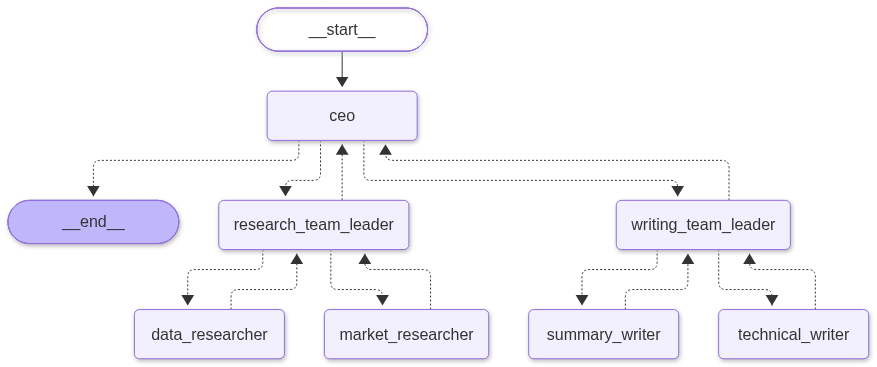

In [35]:
# Print the graph structure in notebook
from IPython.display import Image, display

display(
    Image(
        hierarchical_graph.get_graph().draw_mermaid_png()
    )
)

In [33]:
hierarchical_task = "What are the benefits and risks of AI in healthcare?"

hierarchical_response = hierarchical_graph.invoke({
    "messages": [HumanMessage(content=hierarchical_task)],
    "next_node": "ceo",
    "current_task": hierarchical_task,
    "data_research": "",
    "market_research": "",
    "research_team_output": "",
    "technical_report": "",
    "summary_report": "",
    "writing_team_output": "",
    "final_output": "",
    "task_complete": False
})

In [34]:
print(hierarchical_response["final_output"])

EXECUTIVE SUMMARY
**Executive Summary – Benefits & Risks of AI in Healthcare (Nov 2026)**  

| **Main Findings** | • 70 % of global hospitals use at least one AI‑enabled clinical decision‑support tool (HIMSS 2024).  • > 200 FDA‑cleared AI/ML devices (radiology, pathology, sepsis‑prediction, etc.).  • RCTs show AI improves diagnostic accuracy in ~80 % of studies and cuts sepsis mortality by 10–15 %.  • Economic models project $3–$5 billion annual savings in the U.S. by 2030; AI‑driven drug discovery (AlphaFold) accelerates target ID 3–5×. |
| **Key Benefits** | • **Higher diagnostic accuracy** – e.g., 97 % sensitivity/99 % specificity for breast‑cancer histopathology (JAMA 2023).  • **Faster, earlier detection** – sepsis‑prediction reduces ICU mortality by 12 % (NEJM 2023).  • **Operational efficiencies** – AI triage cuts patient wait times by ~30 % (NHS Digital 2024).  • **Cost reductions** – potential $3–$5 billion annual savings; $12 M hospital savings from predictive nursing alerts 